# Checkpoint distillation — same/cross-checkpoint subliminal transfer

**Question.** How does subliminal (numbers-channel) dog-preference transfer depend on the
pretraining checkpoint of teacher and student?

**Construction.** Teachers = dog **top-5** HP recipes (`dog_top20krungs_configs.json[:5]`),
each LoRA-FT'd (tseed 1) on `EleutherAI/pythia-160m@step{N}`; 100k-prompt `ex10-20` pools,
`prefix` filter; students = **single standard HP** (`ep10_lr1e-4_r8a32`, K/K*≈0.74), ftseed 1,
10k-row subsample (seed 42). Metric everywhere: **test-set prob-scored p(dog)** (50 prompts,
fp32, deterministic) from `preference_eval.json`; storytelling shown where stated.
Campaigns (2026-08-10, queues `ckpt-dog-top5`, `ckpt-dog-fwd`, `ckpt-dog-bwd` under
`run_logs/queue_angela`): diagonal steps {25,50,75,100,125}k; forward +10/+25/+50k capped at
143k (70 cells); backward 125k→{25,70,75,100,110}k and 100k→{25,50,75}k (40 cells).
Sidecar measurements: teacher & raw-base p(dog) per checkpoint (`teachers/dog/ckpt/.../
preference_summary.json`), base-prior ladder every 5k (`animal_selection/ckpt_dog_prior_ladder
.json`), pool forensics (`analysis/ckpt_pool_forensics.json`).

**Row unit in every table below: one student run (single ftseed) or its stated mean over the
5 teacher recipes — no other aggregation.**

In [1]:
import json, math
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

OUT = Path("/mnt/ssd-3/soar-subliminal/angela/outputs")
TAGS = ["ep20_lr1e-4_r16a32", "ep2_lr5e-4_r32a64", "ep7_lr5e-4_r8a8",
        "ep10_lr1e-4_r64a64", "ep20_lr1e-4_r8a16"]
# validated categorical order (dataviz reference palette, light): blue, orange, aqua, yellow, magenta
COLORS = dict(zip(TAGS, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]))
STEPS = [25000, 50000, 75000, 100000, 125000]

rows = []
for f in (OUT / "students/dog/ckpt").glob("*/teacher-pythia-160m@step*/*/ex10-20_prefix_n100k/*/ftseed*/preference_eval.json"):
    d = json.loads(f.read_text())
    j = int(d["base_model"].split("@step")[1]); seg = f.parts[10]
    i = int(seg.split("@step")[1]) if "@step" in seg else j
    rows.append(dict(teacher_step=i, student_step=j, tag=f.parts[11].rsplit("_tseed", 1)[0],
                     ftseed=int(f.parts[-2].removeprefix("ftseed")),
                     p_test=d["sets"]["test"]["p_target"],
                     p_story=d["sets"]["storytelling"]["p_target"] if "storytelling" in d["sets"] else np.nan))
df_all = pd.DataFrame(rows).sort_values(["teacher_step", "student_step", "tag", "ftseed"]).reset_index(drop=True)
# The top5-campaign frame the grid sections use: 5 teacher steps x 5 recipes, ftseed 1.
# (The dense-cliff section below reads df_all, incl. cliff steps and extra ftseeds.)
df = df_all[(df_all.ftseed == 1) & df_all.teacher_step.isin(STEPS)].copy()
print(f"{len(df_all)} student cells on disk; {len(df)} in the top5-campaign frame (ftseed1, 5 steps)")

tb, bb = {}, {}
for s in STEPS:
    for t in TAGS:
        d = json.loads((OUT / f"teachers/dog/ckpt/pythia-160m@step{s}/{t}/preference_summary.json").read_text())["summaries"][0]
        tb[(s, t)] = d["p_target_mean"]; bb[s] = d["base_p_target"]
ladder = {int(k): v["p_dog"] for k, v in json.loads((OUT / "animal_selection/ckpt_dog_prior_ladder.json").read_text())["steps"].items()}
forens = json.loads((OUT / "analysis/ckpt_pool_forensics.json").read_text())["cells"]

157 student cells on disk; 135 in the top5-campaign frame (ftseed1, 5 steps)


## 1. Diagonal: same-checkpoint transfer vs pretraining step

Table: rows = checkpoint step; columns = the 5 teacher recipes (value = that cell's single
student's test p(dog)) + their unweighted mean; right columns = mean teacher p(dog)
(saturates ≈1 everywhere) and the raw checkpoint base p(dog) (flat ≈0.01). Transfer rises
~9× (0.09→0.78) with a takeoff between 75k and 125k that neither teacher strength nor the
base prior explains.

In [2]:
diag = df[df.teacher_step == df.student_step].pivot(index="teacher_step", columns="tag", values="p_test")[TAGS]
diag["mean_5recipes"] = diag.mean(axis=1)
diag["teacher_mean"] = [np.mean([tb[(s, t)] for t in TAGS]) for s in diag.index]
diag["base_p_dog"] = [bb[s] for s in diag.index]
diag.round(3)

tag,ep20_lr1e-4_r16a32,ep2_lr5e-4_r32a64,ep7_lr5e-4_r8a8,ep10_lr1e-4_r64a64,ep20_lr1e-4_r8a16,mean_5recipes,teacher_mean,base_p_dog
teacher_step,,,,,,,,
25000,0.136,0.076,0.076,0.082,0.065,0.087,0.997,0.008
50000,0.186,0.091,0.124,0.075,0.122,0.120,0.997,0.015
75000,0.135,0.082,0.138,0.179,0.129,0.133,0.999,0.012
100000,0.584,0.257,0.286,0.433,0.407,0.394,1.000,0.017
125000,0.815,0.847,0.719,0.914,0.613,0.782,1.000,0.010


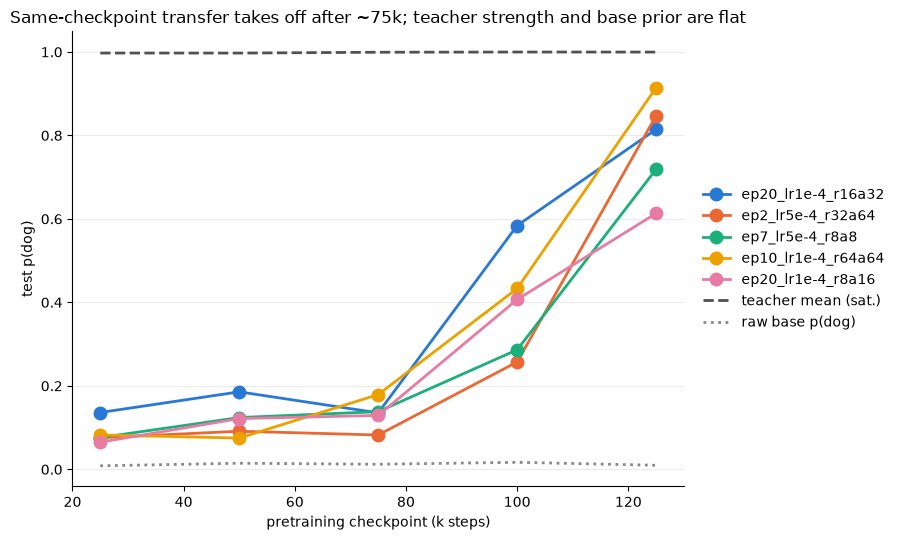

In [3]:
fig, ax = plt.subplots(figsize=(9, 5.5))
for t in TAGS:
    ax.plot(diag.index / 1000, diag[t], "-o", color=COLORS[t], ms=9, lw=2, label=t)
ax.plot(diag.index / 1000, diag["teacher_mean"], "--", color="#52514e", lw=2, label="teacher mean (sat.)")
ax.plot(diag.index / 1000, diag["base_p_dog"], ":", color="#898781", lw=2, label="raw base p(dog)")
ax.set_xlabel("pretraining checkpoint (k steps)"); ax.set_ylabel("test p(dog)")
ax.set_title("Same-checkpoint transfer takes off after ~75k; teacher strength and base prior are flat")
ax.spines[["top", "right"]].set_visible(False); ax.grid(axis="y", alpha=0.25)
ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), frameon=False, fontsize=10)
plt.tight_layout(); plt.show()

## 1b. Dense cliff diagonal (every 5k, single recipe)

Same-checkpoint transfer for `ep20_lr1e-4_r16a32` only, every 5k across the transition
(ckpt-dog-cliff + ckpt-dog-cliffseeds queues). Marker = mean over available student ftseeds
at that step (count annotated when >1); the campaign anchors (25–125k) are the same cells as
§1's first column. Onset sits between 90k and 95k; the ramp is largely complete by
~105–110k.

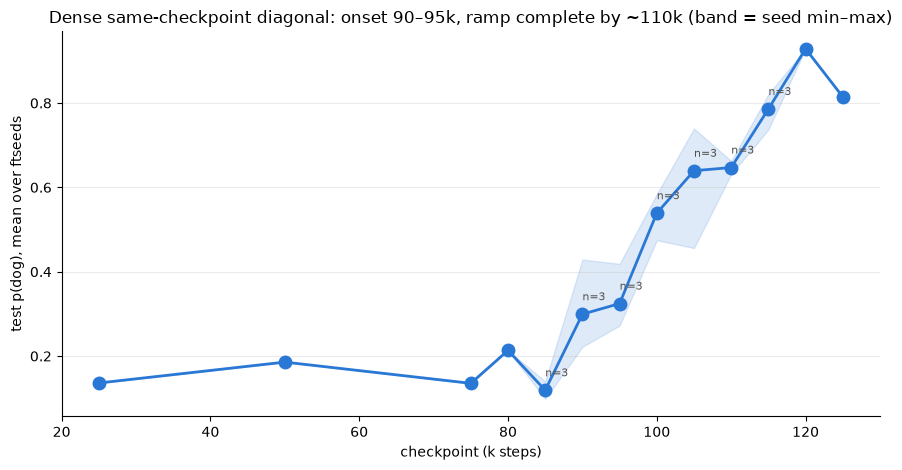

,mean,min,max,count
teacher_step,,,,
25000,0.136,0.136,0.136,1
50000,0.186,0.186,0.186,1
75000,0.135,0.135,0.135,1
80000,0.213,0.213,0.213,1
85000,0.119,0.098,0.140,3
90000,0.299,0.222,0.429,3
95000,0.324,0.272,0.419,3
100000,0.539,0.475,0.584,3
105000,0.639,0.456,0.740,3


In [4]:
cliff = (df_all[(df_all.teacher_step == df_all.student_step)
                & (df_all.tag == "ep20_lr1e-4_r16a32")]
         .groupby("teacher_step").p_test.agg(["mean", "min", "max", "count"]))
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.plot(cliff.index / 1000, cliff["mean"], "-o", color="#2a78d6", ms=9, lw=2)
ax.fill_between(cliff.index / 1000, cliff["min"], cliff["max"], color="#2a78d6", alpha=0.15)
for s, r in cliff.iterrows():
    if r["count"] > 1:
        ax.annotate(f"n={int(r['count'])}", (s / 1000, r["mean"]),
                    textcoords="offset points", xytext=(0, 10), fontsize=8, color="#52514e")
ax.set_xlabel("checkpoint (k steps)"); ax.set_ylabel("test p(dog), mean over ftseeds")
ax.set_title("Dense same-checkpoint diagonal: onset 90–95k, ramp complete by ~110k (band = seed min–max)")
ax.spines[["top", "right"]].set_visible(False); ax.grid(axis="y", alpha=0.25)
plt.tight_layout(); plt.show()
cliff.round(3)

## 2. Full teacher×student grid (diagonal + forward + backward)

Heatmap value = mean over the 5 recipes of test p(dog) (each cell mean of 5 single-seed
students); blank = pair not run. Forward cells (above diagonal) show transfer capped by the
TEACHER's step; backward cells (below) show late pools collapsing in early students —
maturity is required on BOTH sides.

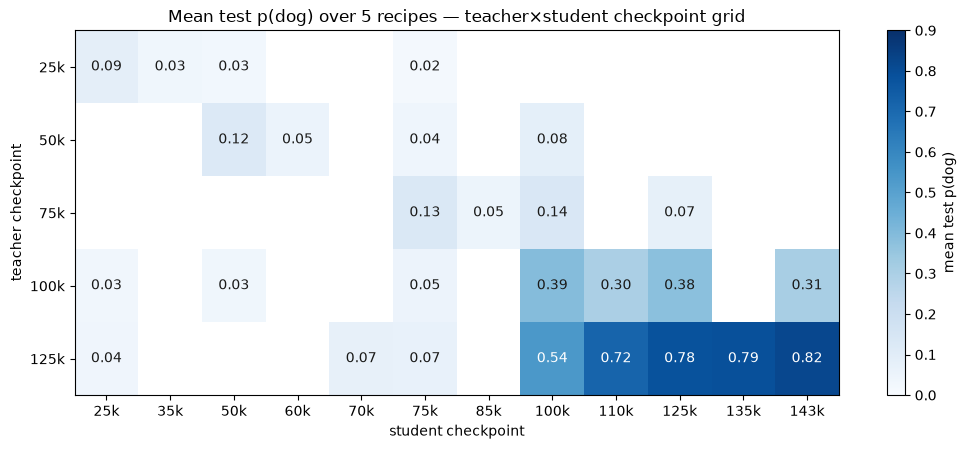

In [5]:
jsteps = sorted(df.student_step.unique())
g = df.groupby(["teacher_step", "student_step"]).p_test.mean()
mat = np.full((len(STEPS), len(jsteps)), np.nan)
for a, i in enumerate(STEPS):
    for b, j in enumerate(jsteps):
        if (i, j) in g.index: mat[a, b] = g[(i, j)]
fig, ax = plt.subplots(figsize=(10.5, 4.6))
im = ax.imshow(mat, cmap="Blues", vmin=0, vmax=0.9, aspect="auto")
ax.set_xticks(range(len(jsteps)), [f"{j//1000}k" for j in jsteps])
ax.set_yticks(range(len(STEPS)), [f"{i//1000}k" for i in STEPS])
ax.set_xlabel("student checkpoint"); ax.set_ylabel("teacher checkpoint")
ax.set_title("Mean test p(dog) over 5 recipes — teacher×student checkpoint grid")
for a in range(len(STEPS)):
    for b in range(len(jsteps)):
        if not np.isnan(mat[a, b]):
            dk = mat[a, b] > 0.45
            ax.text(b, a, f"{mat[a, b]:.2f}", ha="center", va="center",
                    color="#ffffff" if dk else "#1a1a19", fontsize=10)
fig.colorbar(im, ax=ax, label="mean test p(dog)"); plt.tight_layout(); plt.show()

## 3. Distance vs regime

Each cross cell's transfer as a **ratio to the diagonal at min(teacher, student)** step
(diagonal linearly interpolated at unmeasured student steps — marked). Distance explains
little (overall Pearson −0.31); regime explains almost everything: late→late pairs show NO
distance penalty (ratios 1.0–1.34 out to 18k separation), early-teacher cells sit at
0.2–0.5× at every distance, and late teachers *lift* transitional (100k/110k) students above
their own diagonal while doing nothing for pre-transition students.

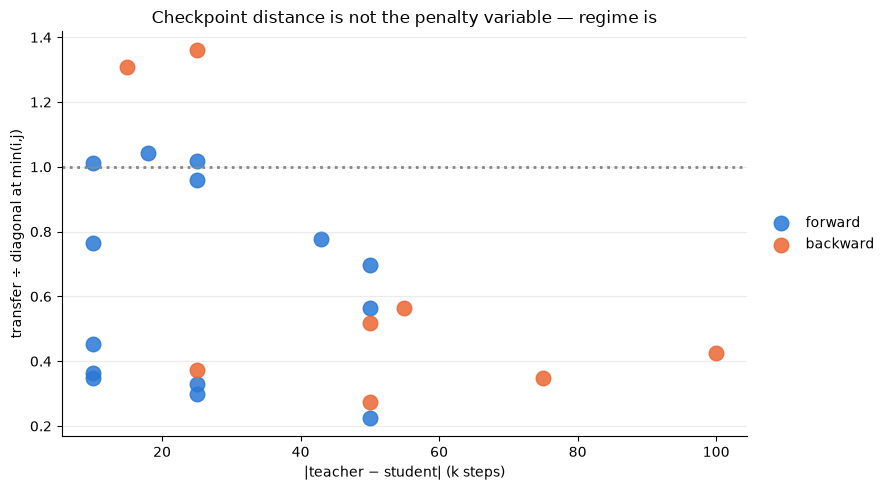

,teacher_step,student_step,p_test,dist_k,direction,ref_interp,ratio_to_diag_at_min
23,125000,110000,0.718,15,backward,True,1.308
14,100000,75000,0.049,25,backward,False,0.372
22,125000,100000,0.536,25,backward,False,1.362
13,100000,50000,0.033,50,backward,False,0.273
21,125000,75000,0.069,50,backward,False,0.517
20,125000,70000,0.074,55,backward,True,0.565
12,100000,25000,0.030,75,backward,False,0.349
19,125000,25000,0.037,100,backward,False,0.425
1,25000,35000,0.032,10,forward,False,0.364
5,50000,60000,0.054,10,forward,False,0.455


In [6]:
dg = {s: diag.loc[s, "mean_5recipes"] for s in STEPS}
def dinterp(s):
    ks = sorted(dg)
    if s <= ks[0]: return dg[ks[0]]
    if s >= ks[-1]: return dg[ks[-1]]
    for a, b in zip(ks, ks[1:]):
        if a <= s <= b:
            w = (s - a) / (b - a); return dg[a] * (1 - w) + dg[b] * w
x = (df.groupby(["teacher_step", "student_step"]).p_test.mean().reset_index()
       .query("teacher_step != student_step"))
x["dist_k"] = (x.student_step - x.teacher_step).abs() // 1000
x["direction"] = np.where(x.student_step > x.teacher_step, "forward", "backward")
x["ref_interp"] = [s not in dg for s in x[["teacher_step", "student_step"]].min(axis=1)]
x["ratio_to_diag_at_min"] = [r.p_test / dinterp(min(r.teacher_step, r.student_step)) for r in x.itertuples()]
fig, ax = plt.subplots(figsize=(9, 5))
for d, c in [("forward", "#2a78d6"), ("backward", "#eb6834")]:
    s = x[x.direction == d]
    ax.scatter(s.dist_k, s.ratio_to_diag_at_min, s=110, color=c, label=d, alpha=0.85)
ax.axhline(1.0, color="#898781", ls=":", lw=2)
ax.set_xlabel("|teacher − student| (k steps)"); ax.set_ylabel("transfer ÷ diagonal at min(i,j)")
ax.set_title("Checkpoint distance is not the penalty variable — regime is")
ax.spines[["top", "right"]].set_visible(False); ax.grid(axis="y", alpha=0.25)
ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), frameon=False)
plt.tight_layout(); plt.show()
x.sort_values(["direction", "dist_k"]).round(3)

## 4. Base p(dog) prior ladder — prior does not explain the takeoff

Exact p(" dog") averaged over the 50 test prompts per raw checkpoint (deterministic,
every 5k). The prior oscillates 0.005–0.018 with no trend; the highest prior of all of
pretraining (65k, 0.0178) sits in the WEAK-transfer regime. Matched-prior pairs straddling
the cliff (70k↔110k Δ0.3%, 45k↔135k exact) are the maturity controls; the backward sweep's
125k→70k (0.074) vs 125k→110k (0.705) realizes the 70k↔110k contrast: ~10× transfer at
identical prior.

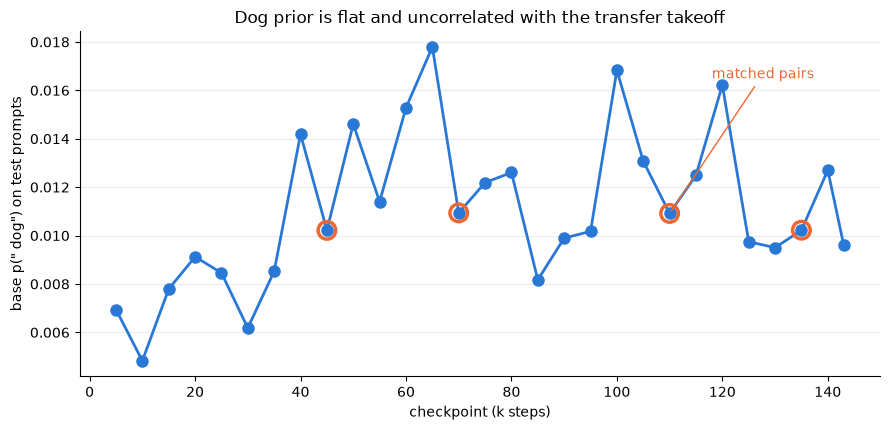

In [7]:
ks = sorted(ladder)
fig, ax = plt.subplots(figsize=(9, 4.4))
ax.plot([k / 1000 for k in ks], [ladder[k] for k in ks], "-o", color="#2a78d6", ms=8, lw=2)
for a, b in [(70000, 110000), (45000, 135000)]:
    ax.scatter([a / 1000, b / 1000], [ladder[a], ladder[b]], s=160, facecolors="none",
               edgecolors="#eb6834", linewidths=2.5, zorder=3)
ax.annotate("matched pairs", xy=(110, ladder[110000]), xytext=(118, 0.0165),
            color="#eb6834", fontsize=10, arrowprops=dict(arrowstyle="-", color="#eb6834"))
ax.set_xlabel("checkpoint (k steps)"); ax.set_ylabel('base p(" dog") on test prompts')
ax.set_title("Dog prior is flat and uncorrelated with the transfer takeoff")
ax.spines[["top", "right"]].set_visible(False); ax.grid(axis="y", alpha=0.25)
plt.tight_layout(); plt.show()

## 5. Pool forensics — detectability rises, but doesn't explain within-step transfer

Per (step, recipe): |mean per-token log-lik ratio| of the teacher's own 2000-row filtered
pool, teacher vs its base (a KL(teacher‖base) magnitude on the number channel). It grows
~10–100× across 25k→125k (Spearman 0.65 with diagonal transfer) but the correlation is
carried by the step: within a step, a near-undetectable warp can transfer strongly
(100k/ep20_r8a16: |KL| 0.004 → 0.41) and a large warp weakly (75k/ep2_r32a64: 0.044 → 0.08).
Signal quantity ≠ transferability; decodability is checkpoint-tied. (Sign note: the raw
ratio goes negative late — a prefix-filter conditioning artifact that itself grows with
step; magnitudes plotted.)

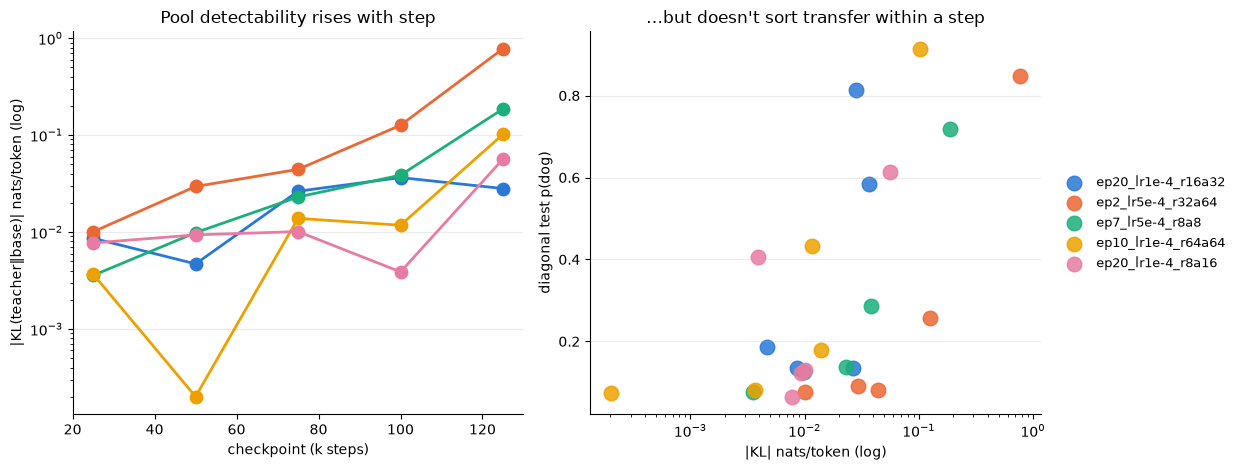

In [8]:
fr = []
for k, v in forens.items():
    s, t = k.split("/"); s = int(s)
    fr.append(dict(step=s, tag=t, abs_kl=abs(v["kl_est_nats_per_token"]),
                   transfer=diag.loc[s, t]))
fr = pd.DataFrame(fr)
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8))
for t in TAGS:
    s = fr[fr.tag == t].sort_values("step")
    axes[0].plot(s.step / 1000, s.abs_kl, "-o", color=COLORS[t], ms=9, lw=2, label=t)
axes[0].set_yscale("log"); axes[0].set_xlabel("checkpoint (k steps)")
axes[0].set_ylabel("|KL(teacher‖base)| nats/token (log)")
axes[0].set_title("Pool detectability rises with step")
for t in TAGS:
    s = fr[fr.tag == t]
    axes[1].scatter(s.abs_kl, s.transfer, s=110, color=COLORS[t], label=t, alpha=0.85)
axes[1].set_xscale("log"); axes[1].set_xlabel("|KL| nats/token (log)")
axes[1].set_ylabel("diagonal test p(dog)")
axes[1].set_title("…but doesn't sort transfer within a step")
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False); ax.grid(axis="y", alpha=0.25)
axes[1].legend(loc="center left", bbox_to_anchor=(1.02, 0.5), frameon=False, fontsize=9)
plt.tight_layout(); plt.show()

## 5b. M2a — numbers-channel entanglement of the dog direction

**Construction.** Per (step, recipe): v_dog = mean_last(teacher) − mean_last(base) on 1024
trait-free ICL number prompts (raw_blocks_v2 basis — captured at the same raw post-block
sites the injection hooks target, avoiding Blank's post-final-LN pitfall). Then inject
α·v_dog (add, raw norm) at ONE block at a time (L0–L11), α∈{1,2}, into the checkpoint's
base on 256 held-out ICL number prompts, and measure the KL of the steered next-token
distribution against unsteered at the last position. Specificity control: a per-layer
NORM-MATCHED random direction (same L2 norm per block, fixed seed per step); the reported
statistic is ratio = KL(v_dog) / KL(random) at matched (layer, α) — i.e. how much more the
dog direction perturbs the numbers channel than an arbitrary direction of the same size.

**Result.** The direction is specifically entangled with the numbers channel at every
checkpoint (peak ratio 3–20×, consistently at L10/L11), rising 25k→75k and then
flattening/dipping — the peak is at 75k, NOT at the transfer cliff, and within a step the
ratio does not order the recipes' transfer. Entanglement of the direction with number
statistics is therefore present long before transfer works and is not the emergent
quantity.

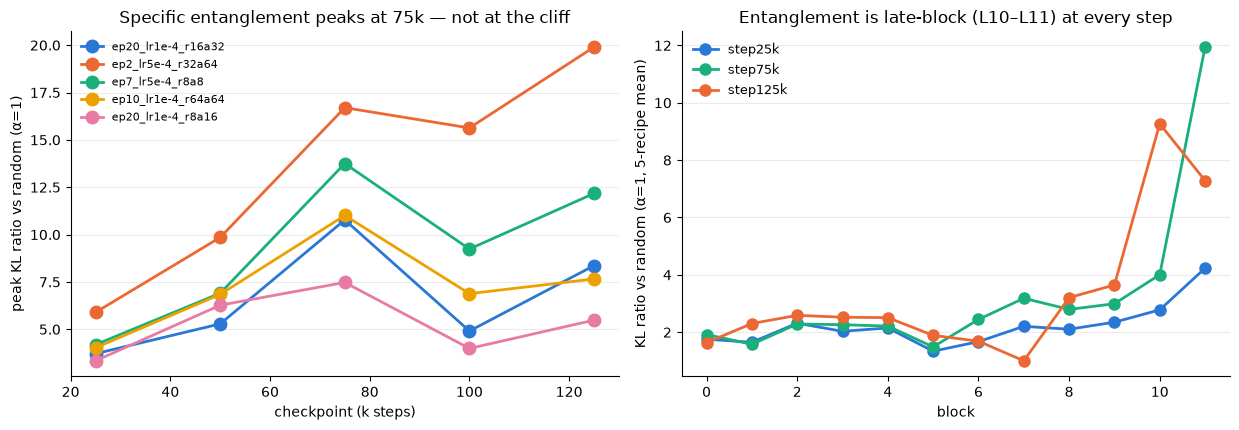

In [9]:
ent = json.loads((OUT / "analysis/ckpt_numbers_entanglement_v2.json").read_text())["cells"]
er = []
for k, v in ent.items():
    st, tag = k.split("/")
    er.append(dict(step=int(st), tag=tag, peak=v["peak_ratio_a1"]))
er = pd.DataFrame(er)
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.4))
for t in TAGS:
    ss = er[er.tag == t].sort_values("step")
    axes[0].plot(ss.step / 1000, ss.peak, "-o", color=COLORS[t], ms=9, lw=2, label=t)
axes[0].set_xlabel("checkpoint (k steps)"); axes[0].set_ylabel("peak KL ratio vs random (α=1)")
axes[0].set_title("Specific entanglement peaks at 75k — not at the cliff")
axes[0].legend(loc="upper left", frameon=False, fontsize=8)
prof = {s: [np.mean([ent[f"{s}/{t}"]["per_layer"][f"L{l}/a1"]["ratio"] for t in TAGS])
            for l in range(12)] for s in (25000, 75000, 125000)}
for (s, vals), c in zip(prof.items(), ["#2a78d6", "#1baf7a", "#eb6834"]):
    axes[1].plot(range(12), vals, "-o", color=c, ms=8, lw=2, label=f"step{s//1000}k")
axes[1].set_xlabel("block"); axes[1].set_ylabel("KL ratio vs random (α=1, 5-recipe mean)")
axes[1].set_title("Entanglement is late-block (L10–L11) at every step")
axes[1].legend(loc="upper left", frameon=False, fontsize=9)
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False); ax.grid(axis="y", alpha=0.25)
plt.tight_layout(); plt.show()

## 6. Steering probes (M1 + M2a, 2026-08-11)

**M1 — steerability screen, self + cross.** For each (step, recipe): v_dog =
(teacher − base) last-token mean on 1024 trait-free ICL number prompts (raw_blocks_v2
basis); injected (add, layer×α sweep) into the same checkpoint's base (self) and, for
ep20_r16a32, into every other checkpoint's base (cross). Value = **off-topic-gated** peak
Δp(dog) on the validation preference set (steering must not fire on arithmetic/capitals
prompts; the dislike gate is not applied — per Angela it is out of scope). **Result:
near-saturated 0.74–0.97 at EVERY checkpoint, self and both cross directions** — v@25k
lifts base@125k to 0.77 and v@125k lifts base@25k to 0.83; no step structure, no trace of
the cliff. (Under the additional dislike gate everything collapses to a flat ~0.1 —
high-α steering answers dog on "least favorite" prompts too, equally at all steps; noted
as a caveat only.)

**M2a — numbers-channel entanglement** (single-block add/raw, α∈{1,2}, ÷ norm-matched
random control): specific 4–20× entanglement at every step, rising 25k→peak at **75k**,
then flat/dipping — also does not track the cliff, and does not order within-step transfer.

Together with the pool forensics (§5): every static, single-direction correlate — signal in
the pools, direction→preference coupling, direction→numbers coupling, direction
transportability — exists at all checkpoints and fails to track the transition. What tracks
it is only the distillation outcome itself, pointing the "why" question at the LEARNING
process (what SGD extracts from number co-occurrence statistics at each checkpoint), not at
static representation geometry. CKA across checkpoints is the queued next probe.

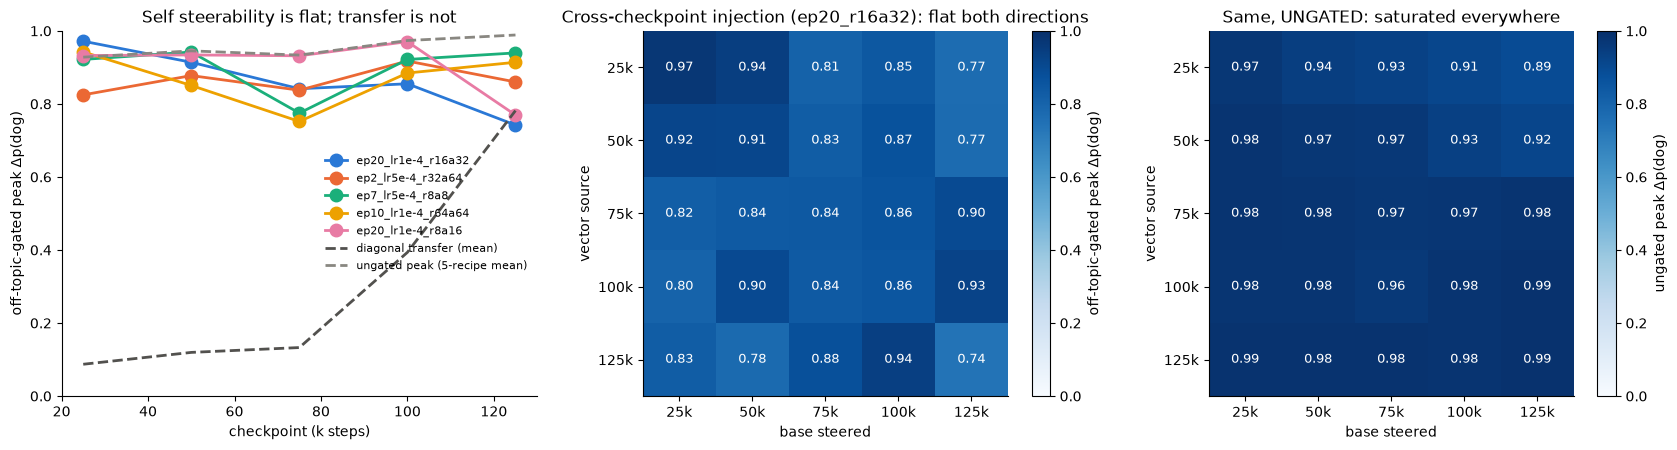

In [10]:
sroot = OUT / "teachers/dog/ckpt"
self_rows, xs = [], {}
for s in STEPS:
    for t in TAGS:
        f = sroot / f"pythia-160m@step{s}" / t / "steerability" / "self" / "aggregate.json"
        if f.exists():
            self_rows.append(dict(step=s, tag=t,
                gated_peak=json.loads(f.read_text())["peaks"]["gated_off"]["delta_val_p_mean"]))
for f in sroot.glob("*/ep20_lr1e-4_r16a32/steerability/steer_*/aggregate.json"):
    d = json.loads(f.read_text())
    src = int(d["base_model"].split("@step")[1])
    tgt = int(str(d["steer_model"]).split("@step")[1])
    xs[(src, tgt)] = d["peaks"]["gated_off"]["delta_val_p_mean"]
sf = pd.DataFrame(self_rows)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
for t in TAGS:
    ss = sf[sf.tag == t]
    axes[0].plot(ss.step / 1000, ss.gated_peak, "-o", color=COLORS[t], ms=9, lw=2, label=t)
axes[0].plot(diag.index / 1000, diag["mean_5recipes"], "--", color="#52514e", lw=2,
             label="diagonal transfer (mean)")
axes[0].set_xlabel("checkpoint (k steps)"); axes[0].set_ylabel("off-topic-gated peak Δp(dog)")
axes[0].set_ylim(0, 1); axes[0].set_title("Self steerability is flat; transfer is not")
axes[0].legend(loc="upper left", frameon=False, fontsize=8)
xs_un = {}
for f in sroot.glob("*/ep20_lr1e-4_r16a32/steerability/steer_*/aggregate.json"):
    d = json.loads(f.read_text())
    xs_un[(int(d["base_model"].split("@step")[1]), int(str(d["steer_model"]).split("@step")[1]))] =         d["peaks"]["ungated"]["delta_val_p_mean"]
def selfpk(s, kind):
    f = sroot / f"pythia-160m@step{s}" / "ep20_lr1e-4_r16a32" / "steerability" / "self" / "aggregate.json"
    return json.loads(f.read_text())["peaks"][kind]["delta_val_p_mean"]
un_rows = []
for st in STEPS:
    for t in TAGS:
        f = sroot / f"pythia-160m@step{st}" / t / "steerability" / "self" / "aggregate.json"
        if f.exists():
            un_rows.append(dict(step=st, tag=t,
                un=json.loads(f.read_text())["peaks"]["ungated"]["delta_val_p_mean"]))
un = pd.DataFrame(un_rows).groupby("step").un.mean()
axes[0].plot(un.index / 1000, un.values, "--", color="#898781", lw=2,
             label="ungated peak (5-recipe mean)")
axes[0].legend(loc="center right", frameon=False, fontsize=8)
mat = np.array([[xs.get((s, t), np.nan) if s != t else selfpk(s, "gated_off")
                 for t in STEPS] for s in STEPS])
mat_un = np.array([[xs_un.get((s, t), np.nan) if s != t else selfpk(s, "ungated")
                    for t in STEPS] for s in STEPS])
im = axes[1].imshow(mat, cmap="Blues", vmin=0, vmax=1.0)
axes[1].set_xticks(range(5), [f"{t//1000}k" for t in STEPS])
axes[1].set_yticks(range(5), [f"{s//1000}k" for s in STEPS])
axes[1].set_xlabel("base steered"); axes[1].set_ylabel("vector source")
axes[1].set_title("Cross-checkpoint injection (ep20_r16a32): flat both directions")
for a in range(5):
    for b in range(5):
        axes[1].text(b, a, f"{mat[a, b]:.2f}", ha="center", va="center", fontsize=9,
                     color="#ffffff" if mat[a, b] > 0.5 else "#1a1a19")
im2 = axes[2].imshow(mat_un, cmap="Blues", vmin=0, vmax=1.0)
axes[2].set_xticks(range(5), [f"{t//1000}k" for t in STEPS])
axes[2].set_yticks(range(5), [f"{s//1000}k" for s in STEPS])
axes[2].set_xlabel("base steered"); axes[2].set_ylabel("vector source")
axes[2].set_title("Same, UNGATED: saturated everywhere")
for a in range(5):
    for b in range(5):
        axes[2].text(b, a, f"{mat_un[a, b]:.2f}", ha="center", va="center", fontsize=9,
                     color="#ffffff" if mat_un[a, b] > 0.5 else "#1a1a19")
fig.colorbar(im, ax=axes[1], label="off-topic-gated peak Δp(dog)")
fig.colorbar(im2, ax=axes[2], label="ungated peak Δp(dog)")
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

## 6b. Cross-checkpoint CKA (raw + PC-ablated)

Minibatch linear CKA between checkpoint BASES, aligned layers (diag of the 13×13 layer
matrix), on a fixed numbers pool (125k ep20_r16a32, identical inputs for every pair) and
held-out Pile; pc5 = CKA after projecting out each side's top-5 held-out-fit principal
components; floor = shuffled baseline (~0.001 everywhere). Pairs chosen against the
transfer grid: fixed +10k offsets, cliff-region consecutive, anchors to final, and the
matched-prior 70k/110k pair. **Result: drift is smooth and uniform — +10k pairs sit at
0.965–0.971 raw at EVERY maturity (25k–35k ≈ 125k–135k), cliff-region pairs show no
reorganization dip, anchors decay smoothly with distance, and PC-ablation preserves the
pattern (differences are not concentrated in dominant PCs). The cliff is invisible to
representational-geometry drift.**

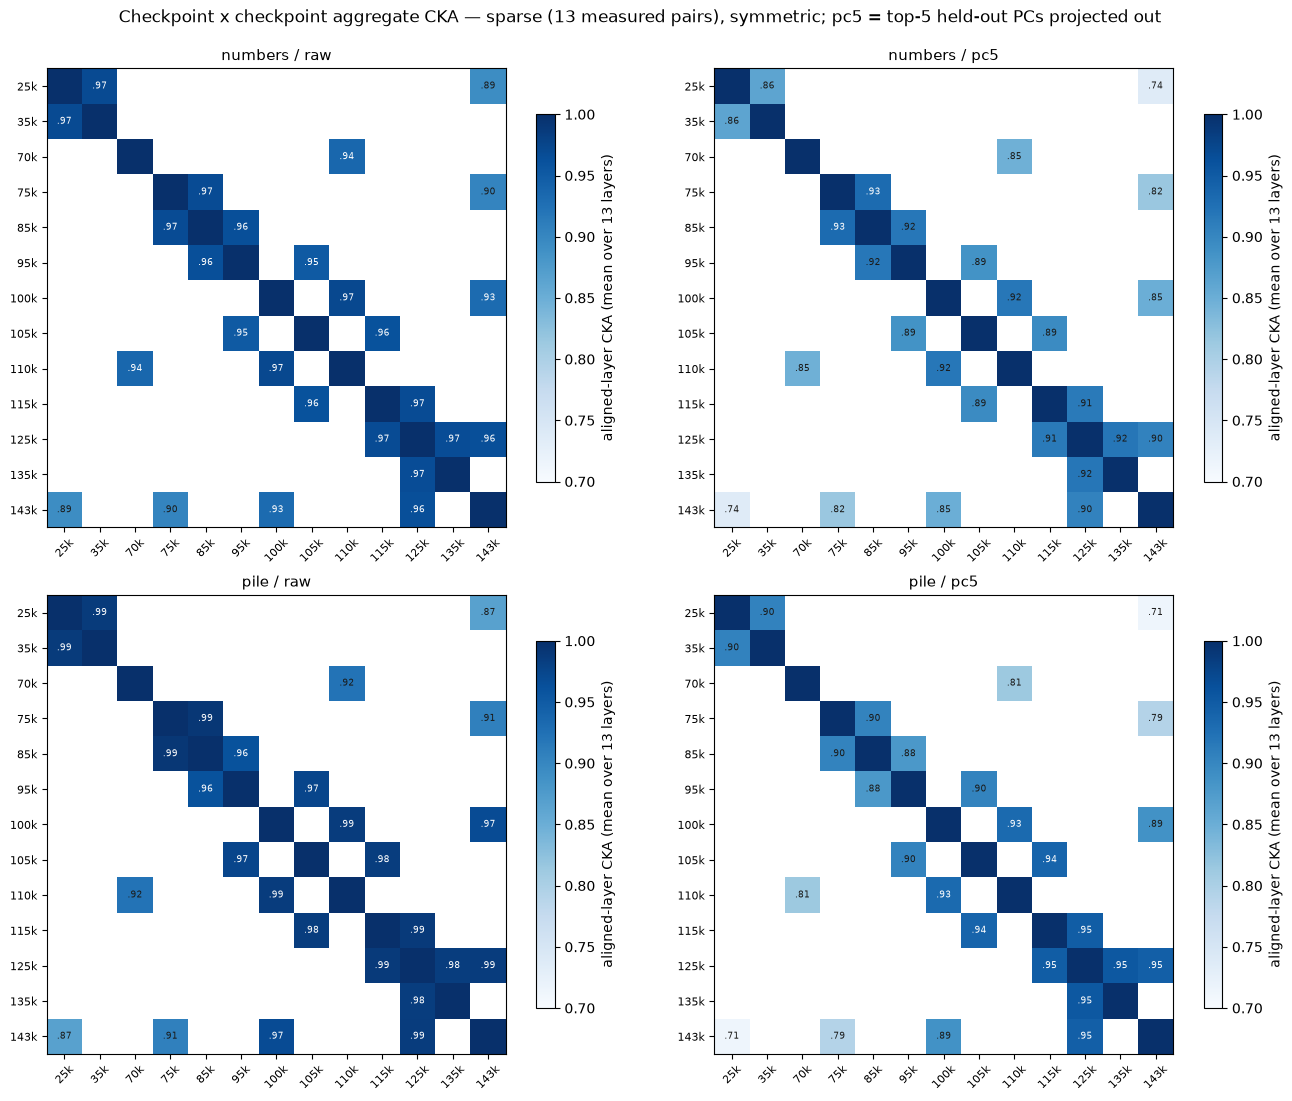

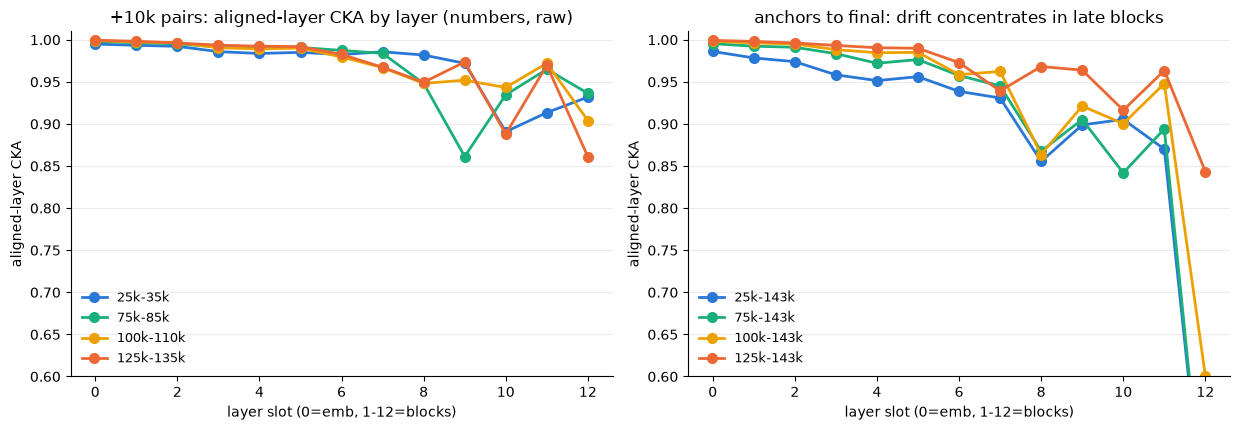

In [11]:
ckroot = OUT / "cka/pairs"
CPAIRS = [(25,35),(75,85),(100,110),(125,135),(85,95),(95,105),(105,115),(115,125),
          (25,143),(75,143),(100,143),(125,143),(70,110)]
def ckmat(a, b, cond="numbers", var="raw"):
    d = ckroot / f"ckpt_{cond}_s{a*1000}_s{b*1000}"
    fs = list(d.glob(f"cka__full-seed0@step{a*1000}__full-seed0@step{b*1000}__{var}.npy"))
    return np.load(fs[0]) if fs else None
# Checkpoint x checkpoint heatmaps: each cell = the AGGREGATE aligned-layer CKA
# (mean of the 13-layer diagonal) for that pair; blank = pair not run (13 pairs measured,
# matrix is sparse and symmetric; diagonal shown as 1 by definition).
KS = [25, 35, 70, 75, 85, 95, 100, 105, 110, 115, 125, 135, 143]
def agg(a, b, cond, var):
    if a == b: return 1.0
    m = ckmat(min(a, b), max(a, b), cond, var)
    return float(np.diag(m).mean()) if m is not None else np.nan
fig, axes = plt.subplots(2, 2, figsize=(13.5, 11))
panels = [("numbers", "raw"), ("numbers", "pc5"), ("pile", "raw"), ("pile", "pc5")]
for ax, (cond, var) in zip(axes.flat, panels):
    M = np.array([[agg(a, b, cond, var) for b in KS] for a in KS])
    im = ax.imshow(M, cmap="Blues", vmin=0.7, vmax=1.0)
    ax.set_xticks(range(len(KS)), [f"{k}k" for k in KS], fontsize=8, rotation=45)
    ax.set_yticks(range(len(KS)), [f"{k}k" for k in KS], fontsize=8)
    ax.set_title(f"{cond} / {var}", fontsize=11)
    for r in range(len(KS)):
        for c in range(len(KS)):
            if not np.isnan(M[r, c]) and r != c:
                ax.text(c, r, f"{M[r, c]:.2f}".lstrip("0"), ha="center", va="center",
                        fontsize=6.5,
                        color="#ffffff" if M[r, c] > 0.93 else "#1a1a19")
    fig.colorbar(im, ax=ax, shrink=0.8, label="aligned-layer CKA (mean over 13 layers)")
fig.suptitle("Checkpoint x checkpoint aggregate CKA — sparse (13 measured pairs), "
             "symmetric; pc5 = top-5 held-out PCs projected out", y=0.995)
plt.tight_layout(); plt.show()
# Aligned-layer profile: diag per pair, to localize WHICH layers drift.
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.4))
for (a, b), c in zip([(25,35),(75,85),(100,110),(125,135)],
                     ["#2a78d6", "#1baf7a", "#eda100", "#eb6834"]):
    axes[0].plot(range(13), np.diag(ckmat(a, b)), "-o", ms=7, lw=2, color=c, label=f"{a}k-{b}k")
axes[0].set_title("+10k pairs: aligned-layer CKA by layer (numbers, raw)")
for (a, b), c in zip([(25,143),(75,143),(100,143),(125,143)],
                     ["#2a78d6", "#1baf7a", "#eda100", "#eb6834"]):
    axes[1].plot(range(13), np.diag(ckmat(a, b)), "-o", ms=7, lw=2, color=c, label=f"{a}k-143k")
axes[1].set_title("anchors to final: drift concentrates in late blocks")
for ax in axes:
    ax.set_xlabel("layer slot (0=emb, 1-12=blocks)"); ax.set_ylabel("aligned-layer CKA")
    ax.set_ylim(0.6, 1.01); ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", alpha=0.25)
    ax.legend(loc="lower left", frameon=False, fontsize=9)
plt.tight_layout(); plt.show()

## 6c. Cross-checkpoint activation patching (causal, per-layer)

**Construction** (`scripts/ckpt_activation_patching.py`): run base@70k and base@110k on the
same 256 ICL number prompts; for each block ℓ (0–11) and each direction, RE-run the
recipient with block ℓ's output replaced by the donor's captured activations (raw
post-block basis, all positions), and measure vs the unpatched recipient: mean
last-position next-token KL, Δ probability mass on digit tokens, and Δ p(" dog") on the
50 test preference prompts. Self-patch control (recipient patched with its own
activations) is exactly 0. 70k↔110k = the matched-prior pair spanning the cliff.

**Read.** Patching perturbs number prediction more the deeper the block, and explodes at
L11 — with a strong asymmetry: 110k's L11 spliced into 70k gives KL ≈ 12.0 and collapses
digit mass by −0.235, while 70k's L11 into 110k gives only 2.4. An asymmetry of this
shape is the signature of a representation PRESENT at 110k with no counterpart at 70k:
the mature model's final-block number-emission code is unreadable by the early model, far
more than vice versa. Δp(dog) ≈ 0 everywhere (raw bases carry no trait). Converges with
M2a (entanglement peak L10–L11) and the pool entropy collapse (an emission-side change):
the checkpoint difference that matters is late-block number-EMISSION machinery.

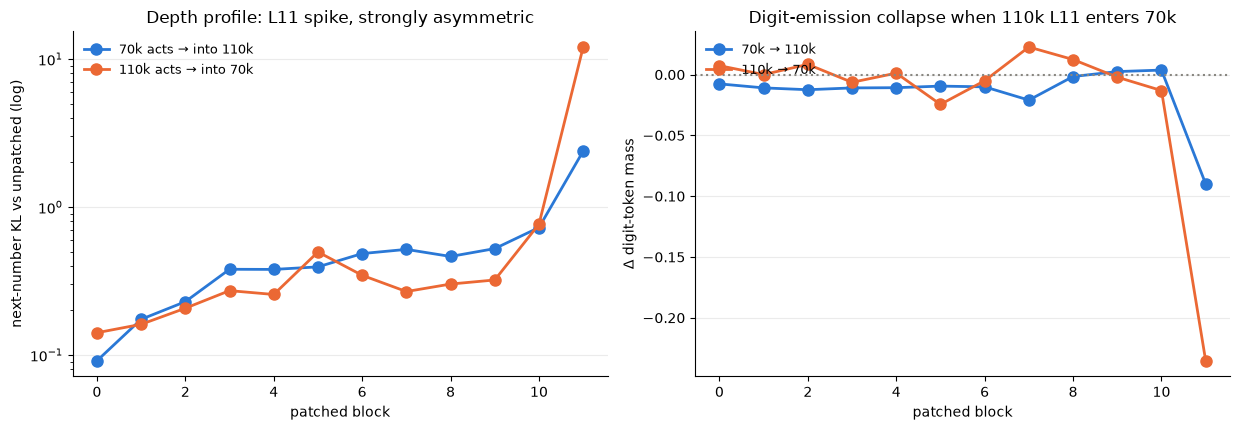

self-patch controls: {'A->B': 0.0, 'B->A': 0.0} | baselines: {'A': {'digit_mass': 0.2360025942325592, 'p_dog': 0.0006749409949406981}, 'B': {'digit_mass': 0.246232271194458, 'p_dog': 0.0005654264241456985}}


,kl_number,d_digit_mass,d_pdog,layer,direction
0,0.0913,-0.0076,-0.0000,0,70k→110k
1,0.1741,-0.0109,-0.0000,1,70k→110k
2,0.2291,-0.0124,-0.0001,2,70k→110k
3,0.3793,-0.0109,-0.0001,3,70k→110k
4,0.3785,-0.0108,-0.0000,4,70k→110k
5,0.3937,-0.0094,-0.0002,5,70k→110k
6,0.4843,-0.0101,-0.0001,6,70k→110k
7,0.5168,-0.0210,-0.0002,7,70k→110k
8,0.4630,-0.0016,-0.0001,8,70k→110k
9,0.5232,0.0025,0.0000,9,70k→110k


In [12]:
pt = json.loads((OUT / "analysis/ckpt_patch_a70000_b110000.json").read_text())
def frame(d):
    pl = pt["directions"][d]["per_layer"]
    return pd.DataFrame([{**pl[f"L{l}"], "layer": l} for l in range(12)])
ab, ba = frame("A->B"), frame("B->A")  # A=70k, B=110k
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.4))
axes[0].plot(ab.layer, ab.kl_number, "-o", ms=8, lw=2, color="#2a78d6",
             label="70k acts → into 110k")
axes[0].plot(ba.layer, ba.kl_number, "-o", ms=8, lw=2, color="#eb6834",
             label="110k acts → into 70k")
axes[0].set_yscale("log"); axes[0].set_xlabel("patched block")
axes[0].set_ylabel("next-number KL vs unpatched (log)")
axes[0].set_title("Depth profile: L11 spike, strongly asymmetric")
axes[1].plot(ab.layer, ab.d_digit_mass, "-o", ms=8, lw=2, color="#2a78d6", label="70k → 110k")
axes[1].plot(ba.layer, ba.d_digit_mass, "-o", ms=8, lw=2, color="#eb6834", label="110k → 70k")
axes[1].axhline(0, color="#898781", ls=":")
axes[1].set_xlabel("patched block"); axes[1].set_ylabel("Δ digit-token mass")
axes[1].set_title("Digit-emission collapse when 110k L11 enters 70k")
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False); ax.grid(axis="y", alpha=0.25)
    ax.legend(loc="upper left", frameon=False, fontsize=9)
plt.tight_layout(); plt.show()
print("self-patch controls:", {d: pt["directions"][d]["self_patch_control_kl"] for d in pt["directions"]},
      "| baselines:", pt["baselines"])
pd.concat([ab.assign(direction="70k→110k"), ba.assign(direction="110k→70k")]).round(4)

## 6d. Teacher-to-teacher activation patching (causal, per-layer)

**Construction** (`--adapter-a/--adapter-b` extension of `scripts/ckpt_activation_patching.py`):
same 256 ICL number + 50 preference prompts as §6c, but both sides are FINE-TUNED teachers
(base@step + ep2_lr5e-4_r32a64 LoRA): A = teacher@75k, B = teacher@125k. Self-patch
controls exactly 0. Direction key is donor→recipient ("A->B" = 75k acts INTO the 125k
teacher) — verified against the script source (`dir_key = f"{donor}->{recipient}"`).

**Baselines** (last position, number prompts): p(dog) 0.098@75k vs 0.225@125k; digit mass
0.239 vs 0.057 — only the late teacher expresses the trait inside the number context.

**Findings.** (1) Late→early ("125k-t acts → into 75k-t"): splicing the late teacher's
L11 state into the early teacher is catastrophic — KL 11.70, digit mass −0.239, p(dog)
−0.098 (→ ~0): the early model cannot decode the late state at all; the same asymmetric
L11 signature as the raw bases (§6c), so the incompatibility belongs to the base
checkpoint, not the adapter. (2) Early→late ("75k-t acts → into 125k-t"): the late
teacher given the early L11 state keeps digit mass (+0.015) but its surface p(dog) RISES
+0.094 (0.225 → 0.32). Mechanistic read: the late teacher's own L11 normally CONVERTS
trait-direction content into concentrated number choices; substituting an L11 without the
conversion machinery lets the raw dog signal leak to the output instead of being encoded
into numbers — L11 at the mature checkpoint is where trait→number-choice encoding lives.


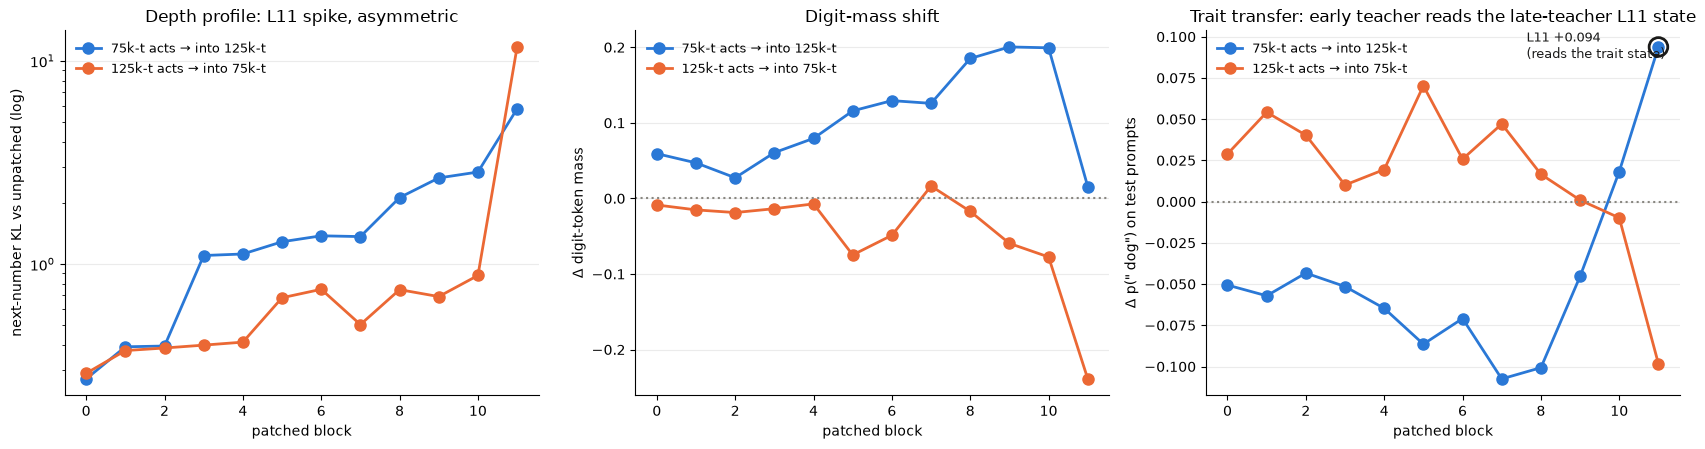

teacher self-patch controls: {'A->B': 0.0, 'B->A': 0.0} | baselines: {'A': {'digit_mass': 0.2391369789838791, 'p_dog': 0.09839154034852982}, 'B': {'digit_mass': 0.05692780762910843, 'p_dog': 0.22455692291259766}}


,kl_number,d_digit_mass,d_pdog,layer,direction
0,0.2720,0.0592,-0.0506,0,75k-t acts → into 125k-t
1,0.3914,0.0470,-0.0571,1,75k-t acts → into 125k-t
2,0.3948,0.0273,-0.0433,2,75k-t acts → into 125k-t
3,1.1011,0.0606,-0.0515,3,75k-t acts → into 125k-t
4,1.1203,0.0795,-0.0647,4,75k-t acts → into 125k-t
5,1.2869,0.1158,-0.0864,5,75k-t acts → into 125k-t
6,1.3766,0.1294,-0.0709,6,75k-t acts → into 125k-t
7,1.3645,0.1258,-0.1075,7,75k-t acts → into 125k-t
8,2.1229,0.1852,-0.1007,8,75k-t acts → into 125k-t
9,2.6522,0.2005,-0.0453,9,75k-t acts → into 125k-t


In [13]:
pt2 = json.loads((OUT / "analysis/ckpt_patch_teachers_a75000_b125000.json").read_text())
def tframe(d):
    pl = pt2["directions"][d]["per_layer"]
    return pd.DataFrame([{**pl[f"L{l}"], "layer": l} for l in range(12)])
tab, tba = tframe("A->B"), tframe("B->A")  # A=75k teacher, B=125k teacher
LAB_AB, LAB_BA = "75k-t acts → into 125k-t", "125k-t acts → into 75k-t"
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
axes[0].plot(tab.layer, tab.kl_number, "-o", ms=8, lw=2, color="#2a78d6", label=LAB_AB)
axes[0].plot(tba.layer, tba.kl_number, "-o", ms=8, lw=2, color="#eb6834", label=LAB_BA)
axes[0].set_yscale("log"); axes[0].set_xlabel("patched block")
axes[0].set_ylabel("next-number KL vs unpatched (log)")
axes[0].set_title("Depth profile: L11 spike, asymmetric")
axes[1].plot(tab.layer, tab.d_digit_mass, "-o", ms=8, lw=2, color="#2a78d6", label=LAB_AB)
axes[1].plot(tba.layer, tba.d_digit_mass, "-o", ms=8, lw=2, color="#eb6834", label=LAB_BA)
axes[1].axhline(0, color="#898781", ls=":")
axes[1].set_xlabel("patched block"); axes[1].set_ylabel("Δ digit-token mass")
axes[1].set_title("Digit-mass shift")
axes[2].plot(tab.layer, tab.d_pdog, "-o", ms=8, lw=2, color="#2a78d6", label=LAB_AB)
axes[2].plot(tba.layer, tba.d_pdog, "-o", ms=8, lw=2, color="#eb6834", label=LAB_BA)
axes[2].axhline(0, color="#898781", ls=":")
star = tab.loc[tab.layer == 11, "d_pdog"].iloc[0]
axes[2].scatter([11], [star], s=180, facecolors="none", edgecolors="#1a1a19", linewidths=2, zorder=4)
axes[2].annotate(f"L11 {star:+.3f}\n(reads the trait state)", (11, star),
                 textcoords="offset points", xytext=(-95, -8), fontsize=9, color="#1a1a19")
axes[2].set_xlabel("patched block"); axes[2].set_ylabel('Δ p(" dog") on test prompts')
axes[2].set_title("Trait transfer: early teacher reads the late-teacher L11 state")
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False); ax.grid(axis="y", alpha=0.25)
    ax.legend(loc="upper left", frameon=False, fontsize=9)
plt.tight_layout(); plt.show()
print("teacher self-patch controls:",
      {d: pt2["directions"][d]["self_patch_control_kl"] for d in pt2["directions"]},
      "| baselines:", pt2["baselines"])
pd.concat([tab.assign(direction=LAB_AB), tba.assign(direction=LAB_BA)]).round(4)

## 6e. Attention-head divergence across the cliff

**Construction** (`ckpt_attn_sim`): for base@70k vs base@110k on 128 ICL number prompts
(eager attention), take each layer×head's real-token L×L attention map, mean over prompts,
and compute the Pearson correlation of the two checkpoints' maps (`pattern_corr`) plus each
side's mean per-head attention entropy (`entropy_a`=70k, `entropy_b`=110k). Row unit: one of
the 144 heads.

**Findings.** Every top-divergent head lives in L7–L11, and every large entropy change is a
SHARPENING (entropy_b < entropy_a) — the mature checkpoint concentrates these heads.
Candidate heads: **L10H5** (corr .59, ent 2.39→1.30), **L7H10** (corr .63, .79→.06),
**L11H11** (corr .70, 1.26→.19). Proposed follow-up: ablate these heads in the 125k teacher
and test whether the pool entropy collapse disappears.

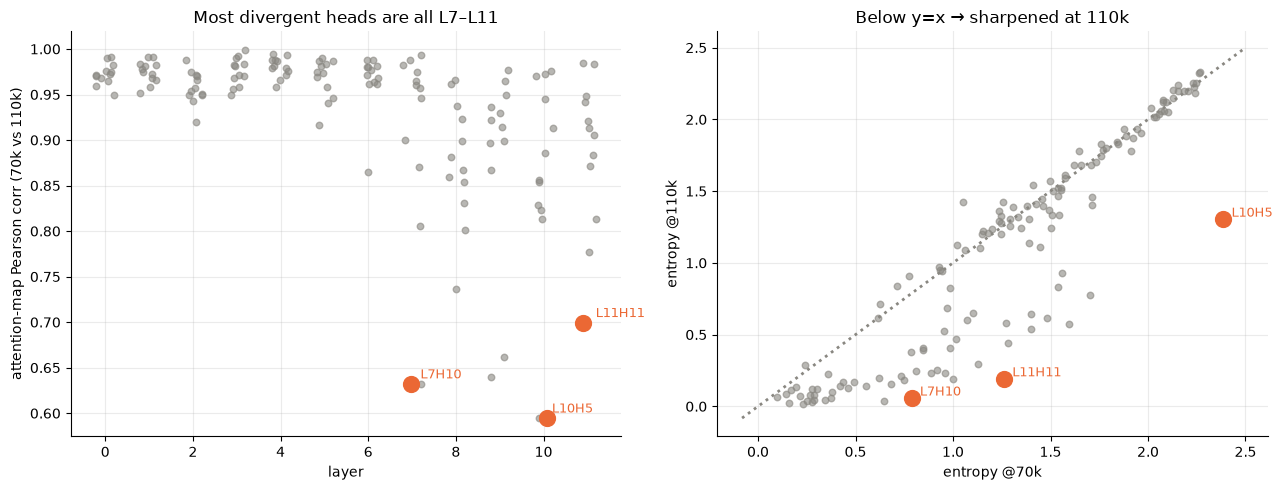

,layer,head,pattern_corr,entropy_a,entropy_b,named
125,10,5,0.595,2.385,1.303,True
94,7,10,0.632,0.787,0.056,True
111,9,3,0.640,1.702,0.776,False
109,9,1,0.662,0.197,0.138,False
143,11,11,0.700,1.261,0.190,True
100,8,4,0.737,0.999,0.190,False
141,11,9,0.777,0.684,0.159,False
97,8,1,0.801,1.073,0.600,False
90,7,6,0.805,1.713,1.462,False
138,11,6,0.813,0.379,0.102,False


In [14]:
asim = json.loads((OUT / "analysis/ckpt_attn_sim_a70000_b110000.json").read_text())
ah = pd.DataFrame(asim["heads"])
named = [(10, 5), (7, 10), (11, 11)]
ah["named"] = [(r.layer, r.head) in named for r in ah.itertuples()]
rng = np.random.default_rng(0)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
jit = rng.uniform(-0.22, 0.22, len(ah))
axes[0].scatter(ah.layer + jit, ah.pattern_corr, s=22, color="#898781", alpha=0.6)
nh = ah[ah.named]
axes[0].scatter(nh.layer + rng.uniform(-0.1, 0.1, len(nh)), nh.pattern_corr, s=130,
                color="#eb6834", zorder=3)
for r in nh.itertuples():
    axes[0].annotate(f"L{r.layer}H{r.head}", (r.layer, r.pattern_corr),
                     textcoords="offset points", xytext=(6, 4), fontsize=9, color="#eb6834")
axes[0].set_xlabel("layer"); axes[0].set_ylabel("attention-map Pearson corr (70k vs 110k)")
axes[0].set_title("Most divergent heads are all L7–L11")
lim = [min(ah.entropy_a.min(), ah.entropy_b.min()) - 0.1, max(ah.entropy_a.max(), ah.entropy_b.max()) + 0.1]
axes[1].plot(lim, lim, ls=":", color="#898781", lw=2)
axes[1].scatter(ah.entropy_a, ah.entropy_b, s=22, color="#898781", alpha=0.6)
axes[1].scatter(nh.entropy_a, nh.entropy_b, s=130, color="#eb6834", zorder=3)
for r in nh.itertuples():
    axes[1].annotate(f"L{r.layer}H{r.head}", (r.entropy_a, r.entropy_b),
                     textcoords="offset points", xytext=(6, 2), fontsize=9, color="#eb6834")
axes[1].set_xlabel("entropy @70k"); axes[1].set_ylabel("entropy @110k")
axes[1].set_title("Below y=x → sharpened at 110k")
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False); ax.grid(alpha=0.25)
plt.tight_layout(); plt.show()
ah.sort_values("pattern_corr").head(10).round(3)

## 6f. Probe transfer across the cliff

**Construction** (`ckpt_probe_transfer`): logistic probes on last-position residuals classify
125k-pool rows vs 25k-pool rows (2000/class, 80/20 split) at each layer slot (0–12). Each
probe is trained on one checkpoint's activations and evaluated both self and zero-shot on the
OTHER checkpoint at the same layer: `acc_self_70k`, `acc_self_110k`,
`acc_70kprobe_on_110k`, `acc_110kprobe_on_70k`.

**Findings.** The pool label is linearly readable at BOTH checkpoints, every layer (self
.70–.83 — even 70k already carries it). Cross-checkpoint transfer decays with depth and
collapses at the top: L12 70k-probe→110k = exactly **0.500** (chance) while self holds ~.80.
It is asymmetric — 110k-probe→70k keeps .675 — so the late-layer feature basis is REWRITTEN
across the cliff: the 110k code subsumes the 70k one but not conversely.

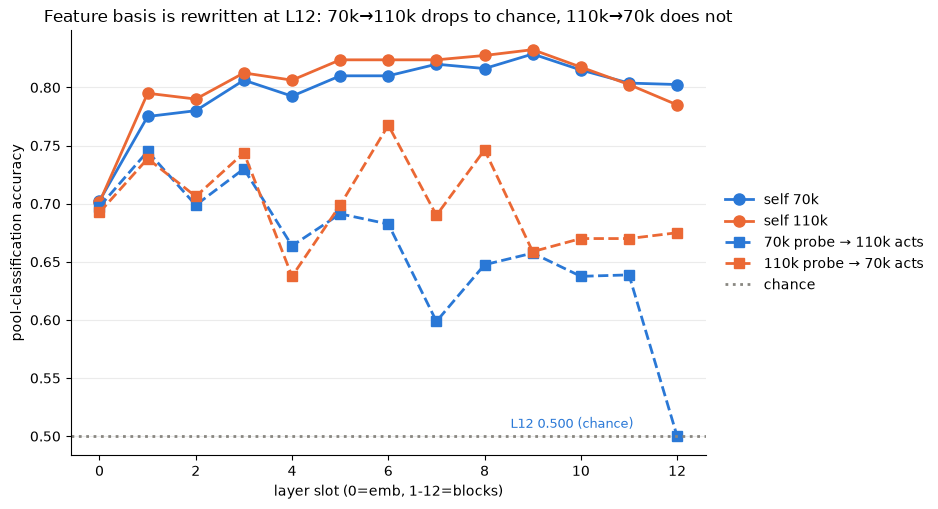

,layer,acc_self_70k,acc_self_110k,acc_70kprobe_on_110k,acc_110kprobe_on_70k
0,0,0.702,0.701,0.698,0.692
1,1,0.775,0.795,0.745,0.739
2,2,0.780,0.790,0.699,0.706
3,3,0.806,0.812,0.730,0.744
4,4,0.792,0.806,0.664,0.638
5,5,0.810,0.824,0.691,0.699
6,6,0.810,0.824,0.682,0.768
7,7,0.820,0.824,0.599,0.690
8,8,0.816,0.828,0.648,0.746
9,9,0.829,0.832,0.658,0.659


In [15]:
prb = pd.DataFrame(json.loads((OUT / "analysis/ckpt_probe_transfer_a70000_b110000.json").read_text())["per_layer"])
fig, ax = plt.subplots(figsize=(9.5, 5.2))
ax.plot(prb.layer, prb.acc_self_70k, "-o", ms=8, lw=2, color="#2a78d6", label="self 70k")
ax.plot(prb.layer, prb.acc_self_110k, "-o", ms=8, lw=2, color="#eb6834", label="self 110k")
ax.plot(prb.layer, prb.acc_70kprobe_on_110k, "--s", ms=7, lw=2, color="#2a78d6",
        label="70k probe → 110k acts")
ax.plot(prb.layer, prb.acc_110kprobe_on_70k, "--s", ms=7, lw=2, color="#eb6834",
        label="110k probe → 70k acts")
ax.axhline(0.5, color="#898781", ls=":", lw=2, label="chance")
col = prb.loc[prb.layer == 12, "acc_70kprobe_on_110k"].iloc[0]
ax.annotate(f"L12 {col:.3f} (chance)", (12, col), textcoords="offset points",
            xytext=(-120, 6), fontsize=9, color="#2a78d6")
ax.set_xlabel("layer slot (0=emb, 1-12=blocks)"); ax.set_ylabel("pool-classification accuracy")
ax.set_title("Feature basis is rewritten at L12: 70k→110k drops to chance, 110k→70k does not")
ax.spines[["top", "right"]].set_visible(False); ax.grid(axis="y", alpha=0.25)
ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), frameon=False, fontsize=10)
plt.tight_layout(); plt.show()
prb.round(3)

## 6g. Entropy-matched pool ablation (CAUSAL)

**Construction** (`run_logs/entropy_match_ablation.py`, log `run_logs/entropy_match_ablation.out`).
Take the 75k `ep2_lr5e-4_r32a64` pool and importance-resample it (first-number unigram target,
n=10k, WITHOUT replacement, seed 0) to match the 125k pool's concentrated first-number profile
(achieved TV 0.324 to the 125k target vs 0.626 for a uniform 10k control). Distill BOTH the
entropy-matched pool and the uniform-resampled control into the 125k student base (standard HP,
ep10, cross-base) and preference-eval. References: the unmodified 75k→125k cell and the 125k
diagonal.

**Result.** Entropy-matched 0.352, uniform control 0.067, unmodified 75k→125k 0.075, 125k
diagonal 0.847. The control lands exactly on the cross floor (the resampling procedure adds
nothing by itself); concentration-matching alone recovers ~40% of the gap to the diagonal.
Number-distribution concentration is a **substantial but PARTIAL** teacher-side carrier; the
residual gap is consistent with signal in finer structure (bigrams / context-conditional
choices) and/or the student-side learning gate.

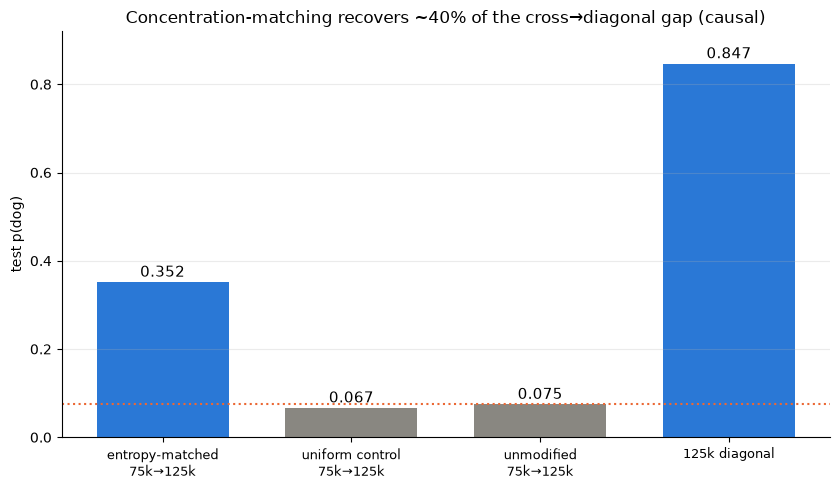

In [16]:
bars = [("entropy-matched\n75k→125k", 0.352, "#2a78d6"),
        ("uniform control\n75k→125k", 0.067, "#898781"),
        ("unmodified\n75k→125k", 0.075, "#898781"),
        ("125k diagonal", 0.847, "#2a78d6")]
fig, ax = plt.subplots(figsize=(8.5, 5))
for i, (lab, v, c) in enumerate(bars):
    ax.bar(i, v, color=c, width=0.7)
    ax.text(i, v + 0.012, f"{v:.3f}", ha="center", fontsize=11)
ax.axhline(0.075, color="#eb6834", ls=":", lw=1.5)
ax.set_xticks(range(4), [b[0] for b in bars], fontsize=9)
ax.set_ylabel("test p(dog)"); ax.set_ylim(0, 0.92)
ax.set_title("Concentration-matching recovers ~40% of the cross→diagonal gap (causal)")
ax.spines[["top", "right"]].set_visible(False); ax.grid(axis="y", alpha=0.25)
plt.tight_layout(); plt.show()

## 7. Working conclusions (2026-08-10)

1. **Same-checkpoint transfer takes off between 75k and 125k** (0.09→0.78 mean) while
   teacher trait strength (≈1.0) and student dog-prior (≈0.01) are flat — neither explains it.
2. **Forward: transfer is capped by the teacher's checkpoint** (100k pools ≈0.39 into any
   later student, incl. final).
3. **Backward: maturity is required on the recipient side too** — 125k pools collapse to
   0.03–0.07 in ≤75k students (below their diagonals), recover through 100k/110k; the
   matched-prior 70k↔110k contrast (~10× at identical prior) pins this on maturity, not prior.
4. **Distance is not the variable; regime is.** Late↔late pairs pay no separation penalty;
   any pre-transition endpoint caps transfer regardless of distance.
5. **Pool warp size is neither necessary nor sufficient** for transfer (§5) — consistent
   with an entangled dog↔numbers representation that must exist in BOTH models and emerges
   ~75k–110k. Next probe: EAS / steerability emergence across the ladder (proposal 3).
6. **Pool entropy collapse + recipe signatures at the cliff** (§5, §6g setup): the teacher's
   number-distribution concentration sharpens across the transition and is the teacher-side
   correlate that tracks transfer — a property of the pool, not of static direction geometry.
7. **Patching (base and teacher) localizes the change to late blocks L10–L11** (§6c, §6d):
   the final-block number-EMISSION code is new at ~110k/125k and asymmetrically incompatible —
   early models can READ the trait-bearing L11 state (early teacher +0.094 p(dog) when fed the
   late state) but cannot GENERATE it.
8. **Attention heads sharpen in L7–L11 across the cliff** (§6e; L10H5, L7H10, L11H11 as a
   candidate circuit) and the linear feature basis is REWRITTEN at L12 (§6f: 70k→110k probe
   drops to chance while the reverse holds) — a directed representational reorganization.
9. **Entropy-matching is causally sufficient for ~40% of transfer** (§6g): concentration is a
   partial teacher-side carrier (control on the cross floor); the remaining gap — finer pool
   structure (bigrams/context) and/or the student-side learning gate — is still open.

Design: 135 student cells (25 diag + 70 fwd + 40 bwd; the loader cell prints the count present at execution). Plus teacher/base evals, prior ladder,
forensics JSON — all under the ckpt/ trees listed in the header.